# Stacked Causal Multi-Head Attention Language Model

**Setup / deviations from the supplied baseline**
- Corpus: `William Shakespeare.txt`, 90/10 train/val split by characters (same for all models).
- Baseline kept: GPT-2 tokenizer (vocab 50,257), context 256, embedding 128, 4 heads, dropout 0.1, AdamW lr 3e-4, 20 epochs, seed 123, batch size 2, stride = context length (non-overlapping windows). **No deviations.**
- Hardware: Google Colab, NVIDIA A100-SXM4-40GB (CUDA).
- Attribution: `GPT_Dataset`, `create_dataloader`, `calc_loss_batch`, `MultiHeadAttention` (plus the `return_shapes` option I added), and the train/eval loops are adapted from the class notebook. `StackedMultiHeadAttention`, `StackedMHALanguageModel`, the sanity tests, the comparison table and the generation loop over models are my own.
- Attention-only model: no feed-forward, residual or LayerNorm layers, as required.

In [ ]:
%pip install -q tiktoken matplotlib

In [ ]:
import tiktoken
import torch
from matplotlib import pyplot as plt
from torch import nn
from torch.utils.data import DataLoader, Dataset

In [ ]:
if torch.cuda.is_available():
    print("Device count:", torch.cuda.device_count())
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("Memory (MB):", torch.cuda.get_device_properties(0).total_memory / (1024**2))
else:
    print("CUDA is not available.")

Device count: 1
GPU Name: NVIDIA A100-SXM4-40GB
Memory (MB): 40441.375


In [ ]:
MODEL_CONFIG = {
    "vocab_size": 50257,
    "context_length": 256,
    "embedding_dim": 128,
    "n_heads": 4,
    "n_layers": 1,
    "drop_rate": 0.1,
}

In [ ]:
with open(r"William Shakespeare.txt", "r", encoding="utf-8") as f:
    text_data = f.read()

# Initialize a tokenizer using the GPT-2 encoding scheme
tokenizer = tiktoken.get_encoding("gpt2")

# Train/validation ratio
train_ratio = 0.9
split_idx = int(train_ratio * len(text_data))

train_data = text_data[:split_idx]
val_data = text_data[split_idx:]

In [ ]:
class GPT_Dataset(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []

        # Tokenize the entire text
        token_ids = tokenizer.encode(txt, allowed_special={"<|endoftext|>"})

        # Use a sliding window to chunk the book into overlapping sequences of max_length
        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i : i + max_length]
            target_chunk = token_ids[i + 1 : i + max_length + 1]

            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]

In [ ]:
def create_dataloader(
    txt,
    batch_size=4,
    max_length=256,
    stride=128,
    shuffle=True,
    drop_last=True,
    num_workers=0,
):
    # Initialize the tokenizer
    tokenizer = tiktoken.get_encoding("gpt2")

    # Create the dataset
    dataset = GPT_Dataset(txt, tokenizer, max_length, stride)

    # Create the dataloader
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
    )
    return dataloader

In [ ]:
# Set the random seed for reproducibility
torch.manual_seed(123)

# Create a DataLoader for the training data with specified parameters
train_loader = create_dataloader(
    train_data,
    batch_size=2,
    max_length=MODEL_CONFIG["context_length"],
    stride=MODEL_CONFIG["context_length"],
    drop_last=True,
    shuffle=True,
    num_workers=0,
)

val_loader = create_dataloader(
    val_data,
    batch_size=2,
    max_length=MODEL_CONFIG["context_length"],
    stride=MODEL_CONFIG["context_length"],
    drop_last=True,
    shuffle=False,
    num_workers=0,
)

In [ ]:
def calc_loss_batch(input_batch, target_batch, model, device):
    # Move the input and target batches to the specified device
    input_batch = input_batch.to(device)
    target_batch = target_batch.to(device)

    # Forward pass through the model: logits [B, T, vocab]
    logits = model(input_batch)

    # Flatten to [B*T, vocab] and [B*T], then cross-entropy
    loss = nn.functional.cross_entropy(
        logits.reshape(-1, logits.size(-1)), target_batch.reshape(-1), reduction="mean"
    )
    return loss

In [ ]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert d_out % num_heads == 0, "d_out must be divisible by num_heads"
        self.num_heads = num_heads
        self.d_head = d_out // num_heads

        # Linear layers for Query, Key, and Value projections
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)

        # Final output projection: after merging heads the width is d_out, so d_out -> d_out
        self.W_out = nn.Linear(d_out, d_out, bias=False)

        self.dropout = nn.Dropout(dropout)

        # Precompute causal mask
        mask = torch.triu(torch.ones(context_length, context_length), diagonal=1)
        self.register_buffer("mask", mask == 1)

    def split_heads(self, x):
        """Reshape input tensor to [batch_size, num_heads, seq_length, d_head]"""
        batch_size, seq_length, _ = x.shape
        x = x.reshape(batch_size, seq_length, self.num_heads, self.d_head)
        return x.permute(0, 2, 1, 3)

    def merge_heads(self, x):
        """Merge heads back to [batch_size, seq_length, d_out]"""
        batch_size, num_heads, seq_length, d_head = x.shape
        x = x.permute(0, 2, 1, 3).contiguous()
        return x.view(batch_size, seq_length, num_heads * d_head)

    def forward(self, x, return_shapes=False):
        _, num_tokens, _ = x.shape
        shapes = {}

        # Compute Q, K, V and split into multiple heads
        queries = self.split_heads(self.W_query(x))
        keys = self.split_heads(self.W_key(x))
        values = self.split_heads(self.W_value(x))
        shapes.update(Q=queries.shape, K=keys.shape, V=values.shape)

        # Compute attention scores
        attn_scores = torch.matmul(queries, keys.transpose(-2, -1))
        shapes["scores"] = attn_scores.shape

        # Apply causal mask
        attn_scores = attn_scores.masked_fill(
            self.mask[:num_tokens, :num_tokens].unsqueeze(0).unsqueeze(0), float("-inf")
        )

        # Scale, softmax, dropout
        attn_weights = torch.softmax(attn_scores / (self.d_head**0.5), dim=-1)
        shapes["weights"] = attn_weights.shape
        attn_weights = self.dropout(attn_weights)

        # Compute weighted sum of values
        context_vectors = torch.matmul(attn_weights, values)

        # Merge heads and apply final projection
        context_vectors = self.merge_heads(context_vectors)
        shapes["merged"] = context_vectors.shape
        out = self.W_out(context_vectors)
        shapes["output"] = out.shape
        return (out, shapes) if return_shapes else out

In [ ]:
# Part 1: shapes for an example batch [2, 6, 128] with 4 heads
mha = MultiHeadAttention(128, 128, MODEL_CONFIG["context_length"], 0.1, 4).eval()
_, s = mha(torch.randn(2, 6, 128), return_shapes=True)
for k, v in s.items():
    print(f"{k:>8}: {tuple(v)}")
assert tuple(s["Q"]) == tuple(s["K"]) == tuple(s["V"]) == (2, 4, 6, 32)
assert tuple(s["scores"]) == tuple(s["weights"]) == (2, 4, 6, 6)
assert tuple(s["merged"]) == tuple(s["output"]) == (2, 6, 128)
assert (mha.W_out.in_features, mha.W_out.out_features) == (128, 128)  # d_out -> d_out
w = torch.softmax(
    torch.randn(1, 1, 6, 6).masked_fill(mha.mask[:6, :6], float("-inf")), -1
)
assert (
    torch.allclose(w.sum(-1), torch.ones(1, 1, 6)) and torch.triu(w[0, 0], 1).sum() == 0
)

       Q: (2, 4, 6, 32)
       K: (2, 4, 6, 32)
       V: (2, 4, 6, 32)
  scores: (2, 4, 6, 6)
 weights: (2, 4, 6, 6)
  merged: (2, 6, 128)
  output: (2, 6, 128)


In [ ]:
class StackedMultiHeadAttention(nn.Module):
    def __init__(
        self,
        d_in,
        d_out,
        context_length,
        dropout,
        num_heads,
        num_layers,
        qkv_bias=False,
    ):
        super().__init__()
        self.layers = nn.ModuleList(
            [
                MultiHeadAttention(
                    d_in if i == 0 else d_out,
                    d_out,
                    context_length,
                    dropout,
                    num_heads,
                    qkv_bias,
                )
                for i in range(num_layers)
            ]
        )

    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

In [ ]:
class StackedMHALanguageModel(nn.Module):
    """token ids -> token emb + pos emb -> n_layers stacked causal MHA -> vocab logits"""

    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["embedding_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["embedding_dim"])
        self.drop = nn.Dropout(cfg["drop_rate"])
        self.stack = StackedMultiHeadAttention(
            d_in=cfg["embedding_dim"],
            d_out=cfg["embedding_dim"],
            context_length=cfg["context_length"],
            dropout=cfg["drop_rate"],
            num_heads=cfg["n_heads"],
            num_layers=cfg["n_layers"],
        )
        self.out_head = nn.Linear(cfg["embedding_dim"], cfg["vocab_size"], bias=False)

    def forward(self, token_ids):  # [B, T] -> [B, T, vocab_size]
        _, T = token_ids.shape
        pos = torch.arange(T, device=token_ids.device)
        x = self.drop(self.tok_emb(token_ids) + self.pos_emb(pos))
        return self.out_head(self.stack(x))

**Heads vs. layers.** More heads inside one MHA layer split the same embedding into several narrower subspaces (d_head = d_out / n_heads) that attend *in parallel* over the same input, so the layer can track several relations at once, but it still performs a single round of "look at other tokens and mix". Stacking layers works *in series*: layer 2 attends over the already-mixed outputs of layer 1, so it can combine information across two hops (attention over attention). Heads add breadth at constant parameter count (each head is narrower); layers add depth and a full new set of Q/K/V/output weights each.

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

N_LAYERS_LIST = [1, 2, 3]  # Models A, B, C
NUM_EPOCHS = 20  # same for all depths
SEED = 123
LR = 3e-4


def build_model(n_layers):
    torch.manual_seed(SEED)  # identical fresh initialization recipe for every depth
    cfg = {**MODEL_CONFIG, "n_layers": n_layers}
    return StackedMHALanguageModel(cfg).to(device)


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

Using device: cuda


In [ ]:
for n in N_LAYERS_LIST:
    m = build_model(n).eval()
    x, y = next(iter(train_loader))
    with torch.no_grad():
        logits = m(x.to(device))
        assert logits.shape == (x.size(0), x.size(1), MODEL_CONFIG["vocab_size"]), (
            logits.shape
        )
        loss = calc_loss_batch(x, y, m, device).item()
        # causality: changing the last token must not change earlier logits
        x2 = x.clone().to(device)
        x2[:, -1] = (x2[:, -1] + 1) % MODEL_CONFIG["vocab_size"]
        assert torch.allclose(m(x2)[:, :-1], logits[:, :-1], atol=1e-5), (
            "causal mask leak"
        )
    print(
        f"n_layers={n}: logits {tuple(logits.shape)}, init loss {loss:.3f}, params {count_params(m):,}"
    )
del m

n_layers=1: logits (2, 256, 50257), init loss 10.819, params 12,964,096
n_layers=2: logits (2, 256, 50257), init loss 10.824, params 13,029,632
n_layers=3: logits (2, 256, 50257), init loss 10.825, params 13,095,168


In [ ]:
def make_optimizer(model):
    return torch.optim.AdamW(model.parameters(), lr=LR)

In [ ]:
def evaluate_loader(dataloader, model, device):
    model.eval()
    total_loss = 0.0
    count = 0

    with torch.no_grad():
        for input_batch, target_batch in dataloader:
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            total_loss += loss.item()
            count += 1

    return total_loss / count

In [ ]:
def train_one_epoch(train_loader, val_loader, model, optimizer, device):
    model.train()
    total_train_loss = 0.0

    for input_batch, target_batch in train_loader:
        # Step 1: Reset gradients before each optimization step
        optimizer.zero_grad()

        # Step 2: Compute loss for current batch
        loss = calc_loss_batch(input_batch, target_batch, model, device)

        # Step 3: Backpropagate gradients through the model
        loss.backward()

        # Step 4: Update weights using the optimizer
        optimizer.step()

        # Step 5: Accumulate the training loss
        total_train_loss += loss.item()

    # Compute the mean training loss for the epoch
    avg_train_loss = total_train_loss / len(train_loader)

    # Evaluate model on validation data
    avg_val_loss = evaluate_loader(val_loader, model, device)

    return avg_train_loss, avg_val_loss

In [ ]:
import time

results = {}  # n_layers -> dict(model, train, val, time)

for n_layers in N_LAYERS_LIST:
    torch.manual_seed(SEED)
    model = build_model(n_layers)
    optimizer = make_optimizer(model)
    train_losses, val_losses = [], []
    start = time.time()
    for epoch in range(NUM_EPOCHS):
        train_loss, val_loss = train_one_epoch(
            train_loader, val_loader, model, optimizer, device
        )
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        print(
            f"[n_layers={n_layers}] Epoch {epoch + 1}/{NUM_EPOCHS} - "
            f"Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}"
        )
    results[n_layers] = {
        "model": model,
        "train": train_losses,
        "val": val_losses,
        "time": time.time() - start,
        "params": count_params(model),
    }

[n_layers=1] Epoch 1/20 - Train Loss: 5.9438, Val Loss: 5.6819
[n_layers=1] Epoch 2/20 - Train Loss: 5.3473, Val Loss: 5.4578
[n_layers=1] Epoch 3/20 - Train Loss: 5.1044, Val Loss: 5.3394
[n_layers=1] Epoch 4/20 - Train Loss: 4.9466, Val Loss: 5.2659
[n_layers=1] Epoch 5/20 - Train Loss: 4.8290, Val Loss: 5.2192
[n_layers=1] Epoch 6/20 - Train Loss: 4.7372, Val Loss: 5.1757
[n_layers=1] Epoch 7/20 - Train Loss: 4.6609, Val Loss: 5.1396
[n_layers=1] Epoch 8/20 - Train Loss: 4.5971, Val Loss: 5.1317
[n_layers=1] Epoch 9/20 - Train Loss: 4.5426, Val Loss: 5.0980
[n_layers=1] Epoch 10/20 - Train Loss: 4.4918, Val Loss: 5.0828
[n_layers=1] Epoch 11/20 - Train Loss: 4.4473, Val Loss: 5.0738
[n_layers=1] Epoch 12/20 - Train Loss: 4.4043, Val Loss: 5.0474
[n_layers=1] Epoch 13/20 - Train Loss: 4.3635, Val Loss: 5.0314
[n_layers=1] Epoch 14/20 - Train Loss: 4.3273, Val Loss: 5.0332
[n_layers=1] Epoch 15/20 - Train Loss: 4.2908, Val Loss: 5.0144
[n_layers=1] Epoch 16/20 - Train Loss: 4.2581, Va

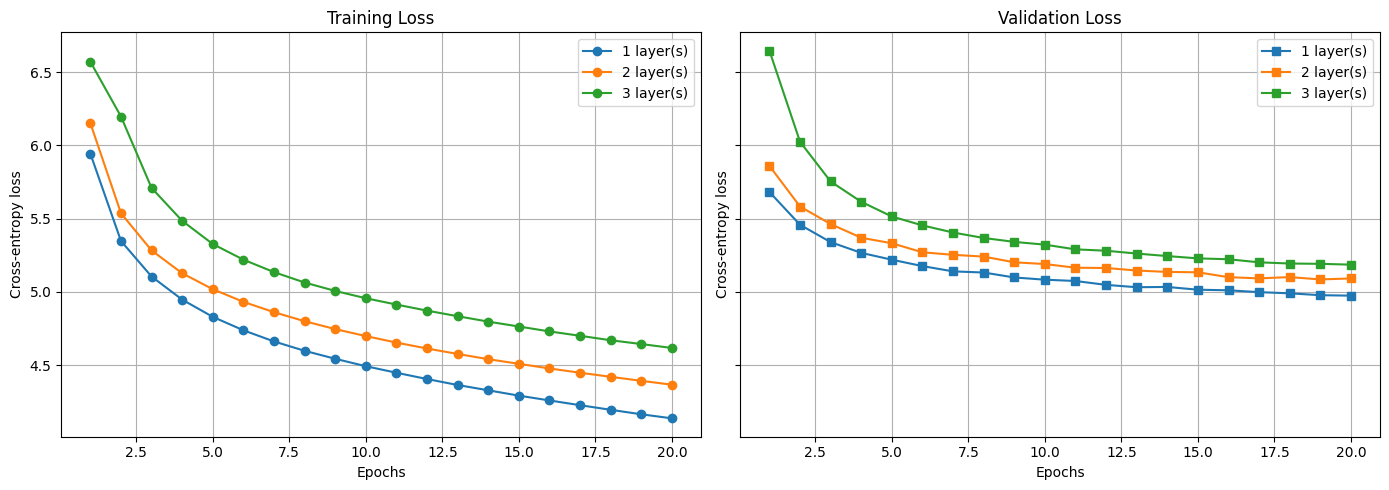

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
epochs = range(1, NUM_EPOCHS + 1)
for n_layers, r in results.items():
    axes[0].plot(epochs, r["train"], marker="o", label=f"{n_layers} layer(s)")
    axes[1].plot(epochs, r["val"], marker="s", label=f"{n_layers} layer(s)")
for ax, title in zip(axes, ["Training Loss", "Validation Loss"]):
    ax.set_xlabel("Epochs")
    ax.set_ylabel("Cross-entropy loss")
    ax.set_title(title)
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
print(
    f"{'layers':>6} {'params':>12} {'final train':>12} {'final val':>10} {'best val (epoch)':>18} {'time (s)':>9}"
)
for n_layers, r in results.items():
    best = min(r["val"])
    print(
        f"{n_layers:>6} {r['params']:>12,} {r['train'][-1]:>12.4f} {r['val'][-1]:>10.4f} "
        f"{best:>10.4f} ({r['val'].index(best) + 1:>2}) {r['time']:>9.1f}"
    )

layers       params  final train  final val   best val (epoch)  time (s)
     1   12,964,096       4.1358     4.9737     4.9737 (20)     259.9
     2   13,029,632       4.3656     5.0912     5.0846 (19)     317.4
     3   13,095,168       4.6165     5.1855     5.1855 (20)     407.5


In [ ]:
@torch.no_grad()
def generate_greedy(model, prompt, max_new_tokens=60):
    model.eval()
    ids = tokenizer.encode(prompt)
    for _ in range(max_new_tokens):
        ctx = torch.tensor([ids[-MODEL_CONFIG["context_length"] :]], device=device)
        next_id = model(ctx)[0, -1].argmax().item()  # logits[:, -1, :] -> greedy token
        ids.append(next_id)  # append so it is part of the next forward pass
    return tokenizer.decode(ids)


PROMPTS = ["To be, or not to be", "Shall I compare thee", "Friends, Romans, countrymen"]
MODEL_NAMES = {1: "A", 2: "B", 3: "C"}
for n_layers, r in results.items():
    print(f"=== Model {MODEL_NAMES[n_layers]} (n_layers={n_layers}) ===")
    for prompt in PROMPTS:
        print(f"[{prompt}] -> {generate_greedy(r['model'], prompt)!r}")
    print()

=== Model A (n_layers=1) ===
[To be, or not to be] -> 'To be, or not to be\nTo make aught of the time\nTo make aught of the world\nTo make a\nTo make a\nTo make a\nTo make aught of the world\nTo make a feast of the world\nOf the world\nOf the world\nOf the world\nOf the world'
[Shall I compare thee] -> 'Shall I compare thee.\n\nPRINCE.\n\nPRINCE.\n\nPRINCE.\n\nPRINCE.\n\nPRINCE.\n\nPRINCE.\n\nPRINCE.\n\nPRINCE.\nPRINCE.\n\nPRINCE.'
[Friends, Romans, countrymen] -> 'Friends, Romans, countrymen,\nAnd,\nAnd I’ll not to be revenged to the world\nAnd I have seen the world\nTo make the world\nTo make thee,\nAnd I have\nAnd I have been\nTo make thee to thee,\nAnd I have been\nTo make thee'

=== Model B (n_layers=2) ===
[To be, or not to be] -> 'To be, or not to be,\nAnd you,\nAnd you,\nAnd you,\nAnd you must be you,\nAnd you,\nAnd you,\nAnd you,\nI’d,\nAnd you,\nAnd you,\nAnd you,\nAnd you,\nAnd you,\nAnd'
[Shall I compare thee] -> 'Shall I compare thee,\nAnd I’ll be revener,\nAnd I’ll be rev

## Written analysis

| Model | Layers | Params | Final train | Final val | Best val (epoch) | Time (s) |
|---|---|---|---|---|---|---|
| A | 1 | 12,964,096 | 4.1358 | 4.9737 | 4.9737 (20) | 259.9 |
| B | 2 | 13,029,632 | 4.3656 | 5.0912 | 5.0846 (19) | 317.4 |
| C | 3 | 13,095,168 | 4.6165 | 5.1855 | 5.1855 (20) | 407.5 |

1. **Did more layers improve validation loss?** No. Val loss worsened with depth (4.974 → 5.091 → 5.186), and A < B < C held at every epoch.

2. **Did train and val loss change the same way?** Both worsened, but train more (+0.23, +0.48 vs. A) than val (+0.12, +0.21). The val − train gap shrank (0.84, 0.73, 0.57), so deeper models are under-optimized, not overfitting. All curves were still falling at epoch 20.

3. **Parameters and time.** Each layer adds only 65,536 parameters (~0.5%), so capacity barely changed. Time grew +22% (B) and +57% (C). With equal wall-clock time, A would get more epochs, which favors A further.

4. **Why might extra layers help, do little, or hurt?** Help: attention over already-mixed outputs allows multi-hop patterns. Little: a small corpus and 20 epochs limit what extra attention can add. Hurt: with no residual connections or LayerNorm, signal and gradients must pass through every layer, which makes deeper stacks slower to train (not tested directly).

*Caveat: one seed, one learning rate, 20 epochs.*

**Why `logits[:, -1, :]`?** Position *t* predicts token *t+1*. Only the last position has seen the whole prompt, so its logits predict the next new token.

**Why append?** The next forward pass must include the chosen token so the model conditions on it. Otherwise it would predict the same token again.

**Samples.** All nine are repetitive and not fluent. A loops on short phrases (`PRINCE.`), B loops and starts producing non-words ("revenit'll"), and C is the most degenerate in two samples (runs of newlines, "not not not"). This matches the val losses, but 3 prompts and one seed are too few to claim a quality ranking. Depth did not reduce repetition here.